# 04 · Land use, cost, and features for a model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/james-kidd/pbn-gradio/blob/main/demos/notebooks/04_land_use_and_features.ipynb)

Paint-by-number asks *what colour is this region?* This asks the
follow-up: *what is it, and what would it cost to do something with it?*

**Read the limitations first.** The labeller is unfitted rules over
visible-band colour with no near-infrared and no ground truth. It is a
feature layer, not a validated classifier, and the notebook surfaces its
own confidence for exactly that reason.

In [1]:
# Bootstrap: clones what it needs in Colab, finds what exists locally.
import pathlib, subprocess, sys

REPO = "https://github.com/james-kidd/pbn-gradio.git"
BRANCH = "main"

def _demos_root():
    for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (base / "nbtools" / "bootstrap.py").exists():
            return base
    dest = (pathlib.Path("/content/pbn-gradio") if pathlib.Path("/content").is_dir()
            else pathlib.Path.cwd() / "pbn-gradio")
    if not (dest / "demos" / "nbtools").exists():
        subprocess.run(["git", "clone", "--depth", "1", "--quiet",
                        "--branch", BRANCH, REPO, str(dest)], check=True)
    return dest / "demos"

sys.path.insert(0, str(_demos_root()))
from nbtools.bootstrap import setup

tk = setup()                           # installs anything missing, first
from nbtools import scenes, display    # these need cv2/matplotlib, so: after

toolkit   /home/user/pbn-gradio  (found locally)
modules   geo, land_use, optimize, pipeline, segmenters, siting, topology
gradio    stubbed (UI layer not needed for these demos)


In [2]:
image = scenes.simple_farm()
working = tk.pipeline.load_and_resize(image, 800)
lab = tk.pipeline.preprocess_rgb(working)
MIN_AREA = int(working.shape[0] * working.shape[1] * 0.001)

seg = tk.segmenters.segment(lab, "felzenszwalb", merge_threshold=8.0,
                            min_area=MIN_AREA, fill=True, n_segments=900,
                            sigma=2.0)   # keeps the thin road alive - see nb 06
labels = seg.labels
print(seg.describe())

felzenszwalb → merge<8 → drop<480px → fill-gaps (9 regions)


## Ground truth lives in one place

Every hectare and every dollar comes from a pixel count times an assumed
ground resolution. `GeoContext` owns that conversion so it cannot be got
wrong in two places differently — and it is the seam where a real
georeferenced raster attaches later.

In [3]:
ctx = tk.geo.GeoContext.from_scale(
    0.5, resize_scale=max(image.shape[:2]) / max(working.shape[:2]))
print(ctx.describe())
print(ctx.export_note())

assumed scale · 0.5000 m/px · not georeferenced (coordinates are pixels)
Coordinates are image pixels, NOT geographic. One pixel is 0.5000 m on the ground, by assumption.


## Features, then labels, then labels again

Adjacency splits into two passes for a real reason. *Neighbour counts* are
pure graph structure — independent of class — so they are available before
labelling and may inform it. The *class fractions* necessarily come after,
since they describe what the neighbours turned out to be. One refinement
pass, then stop: iterating to convergence would be a conditional random
field, which is a different project.

In [4]:
features = tk.land_use.extract_features(working, lab, labels)
tk.land_use.compute_topology(labels, features)     # class-independent
tk.land_use.classify_regions(features)             # first pass
tk.land_use.compute_adjacency(labels, features)    # now classes are known
tk.land_use.classify_regions(features)             # refine with context

print(f"{len(features)} regions, {len({f.class_key for f in features})} distinct classes")

9 regions, 5 distinct classes


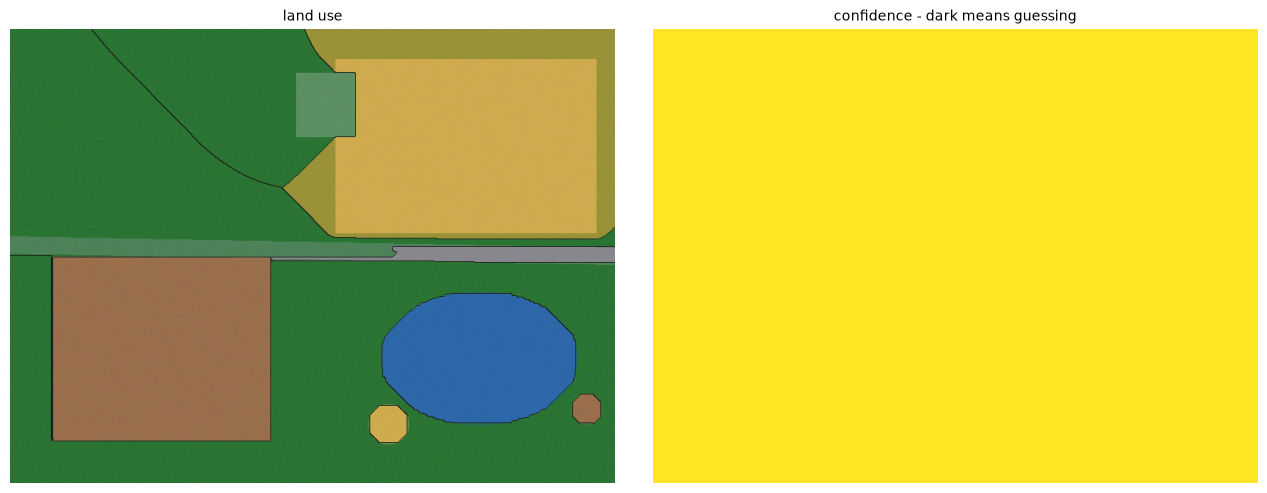

In [5]:
display.grid(
    [tk.land_use.render_label_map(working, labels, features),
     tk.land_use.render_confidence_map(labels, features)],
    ["land use", "confidence - dark means guessing"], columns=2, width=13)

The confidence map is a deliberate output, not a diagnostic. An estimate
that hides its weak spots invites trust it has not earned.

## Cost

`area × base_rate[class] × workability_multiplier`.

The multiplier is the interesting half. Colour tells you a parcel is
scrub; it does not tell you the parcel is a tenth of a hectare,
ragged-edged and walled in by water on three sides — which is what
actually makes it expensive. That information is structural, and it was
already sitting in the segmentation.

In [6]:
rates = tk.land_use.parse_rate_table(tk.land_use.default_rate_table())
costs = tk.land_use.estimate_costs(features, ctx.m_per_px, rates)
frame_ha = ctx.area_ha(working.shape[0] * working.shape[1])

display.markdown(
    tk.land_use.build_cost_report(features, costs, ctx.m_per_px, rates, frame_ha))

### Cost estimate

**Total: $51,729**  ·  12.00 ha surveyed  ·  11.11 ha workable

Of that total, **$35,159** is the material itself and **$16,570** (32%) is the surcharge for how awkward the parcels are to work.

| Class | Parcels | Area (ha) | Rate ($/ha) | Base | Workability | Total |
|---|---:|---:|---:|---:|---:|---:|
| Dense vegetation | 3 | 6.44 | 4,200 | $27,044 | x1.53 | **$41,274** |
| Stressed / senescent vegetation | 2 | 2.71 | 2,400 | $6,507 | x1.34 | **$8,715** |
| Bare soil | 2 | 1.79 | 900 | $1,608 | x1.08 | **$1,739** |
| Water | 1 | 0.89 | 0 | $0 | x1.00 | **$0** |
| Road / track | 1 | 0.17 | 0 | $0 | x1.00 | **$0** |

### How much to trust this

- Mean labelling confidence: **100%**
- Low-confidence parcels (< 45%): **0** of 9, carrying **$0** (0%) of the estimate across **0.00 ha** (0% of surveyed area)
- Ground resolution assumed: **0.500 m/px** — area, and therefore every dollar figure, scales with the square of this number
- Frame coverage: **100.0%** of the 12.00 ha in view is accounted for by a parcel

Treat the low-confidence share as the part of the estimate that needs a human to look at the imagery before anyone commits to it.

## Does shape actually add anything, or does colour do the work?

Cheap to assert, so it gets tested. Each row re-runs labelling and costing
with one more feature family available.

In [7]:
ablation = tk.land_use.run_ablation(labels, features, ctx.m_per_px, rates)
display.markdown(tk.land_use.format_ablation(ablation))

### Does shape and context actually add anything?

Each row re-runs labelling and costing with one more feature family available. *Area relabelled* is the share of ground that changed class when that family was switched on.

| Features available | Total cost | Mean confidence | Classes found | Area relabelled |
|---|---:|---:|---:|---:|
| Colour only | $35,464 | 92% | 5 | — |
| + texture | $41,621 | 93% | 5 | 0.0% |
| + shape | $50,991 | 100% | 5 | 1.4% |
| + context (full) | $51,729 | 100% | 5 | 0.0% |

Colour alone puts the estimate at **$35,464**; the full feature set puts it at **$51,729** — a **+46%** difference, on identical pixels and identical base rates.

The single largest contribution is **+ shape** at $9,370. The smallest is **+ context (full)** at $738.

This measures how much the extra families *change* the answer, not whether they make it correct. Without ground truth the honest claim is that these features carry decision-relevant information a colour-only model structurally cannot access — not that this number is right.

Two honest readings, and the second matters more than the headline:

- **Shape dominates.** Fragmentation and boundary raggedness move the
  estimate harder than anything colour reports.
- **Context is scene-dependent.** It contributes meaningfully on
  fragmented ground and close to nothing on a simple scene, acting almost
  entirely through cost rather than labelling. Not a general-purpose win.

Change the first cell to `scenes.fragmented()` to see the second point
directly.

The ablation measures how much the extra families *change* the answer,
not whether they make it *correct*. Without ground truth that is the
strongest claim available.

## Export for a downstream model

The flat CSV is for training. The JSON carries the same rows plus the
scored evidence behind each label and the cost drivers behind each
estimate, with every column tagged by feature family.

That tagging is the point: an attribution over these inputs reads as an
explanation, because each input already means something in the world.

In [8]:
import csv, json, tempfile

records = tk.land_use.export_features(features, costs)
csv_path, json_path = tk.land_use.write_feature_export(records, tempfile.mkdtemp())

with open(csv_path) as fh:
    rows = list(csv.reader(fh))
display.table([r[:7] for r in rows[1:6]], rows[0][:7])

schema = json.load(open(json_path))["schema"]
display.table([[s["column"], s["family"], s["description"]] for s in schema],
              ["column", "family", "description"])

| region_id | centroid_x | centroid_y | area_px | area_ha | lab_l | lab_a |
|---|---|---|---|---|---|---|
| 1 | 606.3 | 140.6 | 106367 | 2.65918 | 67.22115 | -10.15966 |
| 2 | 308.5 | 84.6 | 44967 | 1.12418 | 28.67312 | -26.06783 |
| 3 | 179.5 | 190.8 | 86301 | 2.15753 | 23.81237 | -26.30898 |
| 4 | 628.6 | 298.5 | 6792 | 0.1698 | 59.64716 | -1.04629 |
| 5 | 439.1 | 471.5 | 126292 | 3.1573 | 17.91922 | -30.44392 |

| column | family | description |
|---|---|---|
| area_px | shape | region size in pixels |
| area_ha | shape | region size on the ground |
| lab_l | colour | CIELAB lightness |
| lab_a | colour | CIELAB green-red axis |
| lab_b | colour | CIELAB blue-yellow axis |
| hue_deg | colour | circular-mean hue |
| saturation | colour | HSV saturation |
| exg | colour | excess green (visible-band vegetation proxy) |
| l_std | texture | internal lightness variation |
| edge_density | texture | mean gradient magnitude |
| shape_index | shape | perimeter / (2*sqrt(pi*area)); 1.0 is a circle |
| elongation | shape | major axis / minor axis |
| solidity | shape | area / convex hull area |
| neighbour_count | context | number of distinct regions touched |
| obstructed_frac | context | share of border against water or structure |
| road_frac | context | share of border against road |

In [9]:
example = next(r for r in records if r["evidence"])
print(f"region {example['region_id']}  ->  {example['predicted_class']} "
      f"({example['confidence']:.0%})\n")
for item in example["evidence"]:
    print(f"  {item['weight']:+.2f}  [{item['family']:7s}] {item['reason']}")

region 1  ->  stressed_veg (100%)

  +1.80  [colour ] yellow hue
  +1.00  [colour ] warm (high LAB b*)
  +0.80  [colour ] chlorophyll fading but present
  +0.27  [colour ] bright


That block is the whole argument for region-level features. *"A road
because it is twelve times longer than wide and touches four parcels"* is
a claim you can verify by looking at the picture. *"A road because channel
47 activated"* is not.